In [1]:
AQHI_THRESHOLD = 4

from pathlib import Path
import pandas as pd

data_path = Path("data/processed/tuen_mun_aqhi.csv")
if not data_path.exists():
    data_path = Path("tuen_mun_aqhi.csv")
if not data_path.exists():
    raise FileNotFoundError(
        "Upload tuen_mun_aqhi.csv in Colab, or run from the repository root."
    )

data = pd.read_csv(
    data_path,
    dtype={"aqhi": "float64", "is_substituted": "bool"},
)
data["timestamp"] = pd.to_datetime(
    data["timestamp"], utc=True, errors="raise"
).dt.tz_convert("Asia/Hong_Kong")
data = data.sort_values("timestamp").reset_index(drop=True)

print("First five observations:")
print(data.head().to_string(index=False))


First five observations:
                timestamp  aqhi  is_substituted
2025-04-01 01:00:00+08:00   2.0           False
2025-04-01 02:00:00+08:00   2.0           False
2025-04-01 03:00:00+08:00   2.0           False
2025-04-01 04:00:00+08:00   2.0           False
2025-04-01 05:00:00+08:00   2.0           False


In [2]:
assert list(data.columns) == ["timestamp", "aqhi", "is_substituted"]
assert not data.empty
assert data["timestamp"].notna().all()
assert data["timestamp"].is_unique, "Review duplicate timestamps."

expected_hours = pd.date_range(
    start=data["timestamp"].min(),
    end=data["timestamp"].max(),
    freq="h",
)
missing_hours = expected_hours.difference(pd.DatetimeIndex(data["timestamp"]))
assert len(missing_hours) == 0, "Review missing hours before building targets."

available_aqhi = data["aqhi"].dropna()
assert available_aqhi.isin(range(1, 12)).all(), "Review AQHI codes."

quality_summary = pd.Series({
    "Hourly rows": len(data),
    "Available AQHI readings": int(data["aqhi"].notna().sum()),
    "Missing AQHI readings": int(data["aqhi"].isna().sum()),
    "Duplicate timestamps": int(data["timestamp"].duplicated().sum()),
    "Missing hours": len(missing_hours),
    "Substituted readings": int(data["is_substituted"].sum()),
    "10+ category encoded as 11": int(data["aqhi"].eq(11).sum()),
})
print(quality_summary.to_string())
print("First timestamp:", data["timestamp"].min())
print("Last timestamp:", data["timestamp"].max())


Hourly rows                   10944
Available AQHI readings       10926
Missing AQHI readings            18
Duplicate timestamps              0
Missing hours                     0
Substituted readings           1083
10+ category encoded as 11       15
First timestamp: 2025-04-01 01:00:00+08:00
Last timestamp: 2026-07-01 00:00:00+08:00


In [3]:
high_count = int(available_aqhi.ge(AQHI_THRESHOLD).sum())
other_count = int(available_aqhi.lt(AQHI_THRESHOLD).sum())
class_counts = pd.Series({
    "AQHI below 4": other_count,
    "AQHI at least 4": high_count,
})
print(class_counts.to_string())
print(f"AQHI >= 4 share among available readings: {high_count / len(available_aqhi):.2%}")
print(f"Available readings below 4: {other_count / len(available_aqhi):.2%}")
print("Missing measurements remain missing:", int(data["aqhi"].isna().sum()))


AQHI below 4       6627
AQHI at least 4    4299
AQHI >= 4 share among available readings: 39.35%
Available readings below 4: 60.65%
Missing measurements remain missing: 18


In [4]:
import hashlib
import json
import platform
import warnings
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid, TimeSeriesSplit
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score,
    accuracy_score, average_precision_score, precision_recall_curve,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings('error', category=ConvergenceWarning)
warnings.filterwarnings('error', category=RuntimeWarning)
SEED = 3004
HORIZON = pd.Timedelta(hours=6)
TEST_START = pd.Timestamp('2026-04-01 00:00', tz='Asia/Hong_Kong')
TEST_END = pd.Timestamp('2026-07-01 00:00', tz='Asia/Hong_Kong')
output_dir = Path('outputs/aqhi4-3h')
figure_dir = output_dir / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 120})

In [5]:
observations = data.set_index('timestamp')
features = pd.DataFrame(index=observations.index)
features['aqhi_now'] = observations['aqhi']
for lag in (1, 2, 3):
    features[f'aqhi_lag_{lag}h'] = observations['aqhi'].reindex(
        features.index - pd.Timedelta(hours=lag)
    ).to_numpy()
features['aqhi_change_3h'] = features['aqhi_now'] - features['aqhi_lag_3h']
features['hour_sin'] = np.sin(2 * np.pi * features.index.hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * features.index.hour / 24)
feature_columns = list(features.columns)

samples = features.copy()
samples['target_time'] = samples.index + HORIZON
samples['actual_aqhi'] = observations['aqhi'].reindex(samples.target_time).to_numpy()
samples['input_substituted'] = observations['is_substituted'].to_numpy()
samples['target_substituted'] = observations['is_substituted'].reindex(
    samples.target_time, fill_value=False
).to_numpy()
samples['any_input_substituted'] = samples['input_substituted']
for lag in (1, 2, 3):
    lag_flag = observations['is_substituted'].reindex(
        samples.index - pd.Timedelta(hours=lag), fill_value=False
    ).to_numpy()
    samples['any_input_substituted'] |= lag_flag

missing_features = samples[feature_columns].isna().any(axis=1)
missing_targets = samples['actual_aqhi'].isna()
complete = samples.loc[~missing_features & ~missing_targets].copy()
complete['actual_class'] = complete['actual_aqhi'].ge(AQHI_THRESHOLD).astype(int)
train = complete.loc[(complete.index < TEST_START) & (complete.target_time < TEST_START)].copy()
test = complete.loc[(complete.index >= TEST_START) & (complete.target_time <= TEST_END)].copy()
assert len(train) and len(test)
assert train.target_time.max() < test.index.min()
assert train.index.intersection(test.index).empty
assert train.actual_class.nunique() == 2
assert test.actual_class.nunique() == 2

split_summary = pd.DataFrame([
    {'split': name, 'samples': len(frame), 'positive_samples': int(frame.actual_class.sum()),
     'negative_samples': int(frame.actual_class.eq(0).sum()),
     'first_input_time': frame.index.min(), 'last_input_time': frame.index.max(),
     'last_target_time': frame.target_time.max(),
     'substituted_targets': int(frame.target_substituted.sum())}
    for name, frame in [('train', train), ('test', test)]
])
split_summary.to_csv(output_dir / 'split_summary.csv', index=False)
exclusions = pd.Series({
    'input_rows': len(samples), 'rows_with_missing_features': int(missing_features.sum()),
    'rows_with_missing_or_unavailable_targets': int(missing_targets.sum()),
    'rows_with_both': int((missing_features & missing_targets).sum()),
    'complete_rows': len(complete),
    'excluded_complete_rows_across_split_boundary': len(complete) - len(train) - len(test),
})
exclusions.to_csv(output_dir / 'sample_accounting.csv', header=['count'])
print(split_summary.to_string(index=False))
print(exclusions.to_string())
print(train[feature_columns + ['target_time', 'actual_class']].head().to_string())

split  samples  positive_samples  negative_samples          first_input_time           last_input_time          last_target_time  substituted_targets
train     8732              3718              5014 2025-04-01 04:00:00+08:00 2026-03-31 17:00:00+08:00 2026-03-31 23:00:00+08:00                  411
 test     2153               581              1572 2026-04-01 00:00:00+08:00 2026-06-30 18:00:00+08:00 2026-07-01 00:00:00+08:00                  655
input_rows                                      10944
rows_with_missing_features                         33
rows_with_missing_or_unavailable_targets           24
rows_with_both                                      4
complete_rows                                   10891
excluded_complete_rows_across_split_boundary        6
                           aqhi_now  aqhi_lag_1h  aqhi_lag_2h  aqhi_lag_3h  aqhi_change_3h  hour_sin      hour_cos               target_time  actual_class
timestamp                                                              

In [6]:
X_train, y_train = train[feature_columns], train.actual_class
X_test, y_test = test[feature_columns], test.actual_class
splitter = TimeSeriesSplit(n_splits=3, gap=6)
folds = list(splitter.split(X_train))
fold_records = []
for number, (fit_rows, validation_rows) in enumerate(folds, start=1):
    assert train.iloc[fit_rows].target_time.max() < train.index[validation_rows].min()
    assert y_train.iloc[fit_rows].nunique() == 2
    assert y_train.iloc[validation_rows].sum() > 0
    fold_records.append({
        'fold': number, 'fit_samples': len(fit_rows), 'validation_samples': len(validation_rows),
        'fit_last_target': train.iloc[fit_rows].target_time.max(),
        'validation_start': train.index[validation_rows].min(),
        'validation_end': train.index[validation_rows].max(),
        'validation_positives': int(y_train.iloc[validation_rows].sum()),
    })
pd.DataFrame(fold_records).to_csv(output_dir / 'validation_folds.csv', index=False)

model_specs = {
    'Decision Tree': (DecisionTreeClassifier(random_state=SEED), {
        'max_depth': [3, 5], 'min_samples_leaf': [10, 30], 'class_weight': [None, 'balanced']}),
    'Random Forest': (RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEED), {
        'max_depth': [5, None], 'min_samples_leaf': [5, 20], 'class_weight': [None, 'balanced']}),
    'Logistic Regression': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED)), {
        'logisticregression__C': [0.1, 1.0, 10.0], 'logisticregression__class_weight': [None, 'balanced']}),
    'KNN': (make_pipeline(StandardScaler(), KNeighborsClassifier()), {
        'kneighborsclassifier__n_neighbors': [5, 15, 31], 'kneighborsclassifier__weights': ['uniform', 'distance']}),
    'SVM': (make_pipeline(StandardScaler(), SVC(kernel='rbf', gamma='scale', cache_size=512, random_state=SEED)), {
        'svc__C': [0.1, 1.0, 10.0], 'svc__class_weight': [None, 'balanced']}),
}

def scores_for(estimator, X):
    if hasattr(estimator, 'predict_proba'):
        scores = estimator.predict_proba(X)[:, 1]
    else:
        scores = estimator.decision_function(X)
    assert np.isfinite(scores).all()
    return scores

def select_threshold(truth, scores):
    precision, recall, thresholds = precision_recall_curve(truth, scores)
    f1_values = np.divide(2 * precision[:-1] * recall[:-1], precision[:-1] + recall[:-1],
                          out=np.zeros(len(thresholds)), where=(precision[:-1] + recall[:-1]) > 0)
    best = max(range(len(thresholds)), key=lambda i: (f1_values[i], precision[i], thresholds[i]))
    return float(thresholds[best]), float(f1_values[best])

selected = {}
search_records = []
for name, (base_estimator, grid) in model_specs.items():
    candidates = []
    for parameters in ParameterGrid(grid):
        validation_scores, validation_truth, validation_times = [], [], []
        for fit_rows, validation_rows in folds:
            estimator = clone(base_estimator).set_params(**parameters)
            estimator.fit(X_train.iloc[fit_rows], y_train.iloc[fit_rows])
            validation_scores.extend(scores_for(estimator, X_train.iloc[validation_rows]))
            validation_truth.extend(y_train.iloc[validation_rows])
            validation_times.extend(X_train.index[validation_rows])
        validation_scores = np.asarray(validation_scores)
        validation_truth = np.asarray(validation_truth)
        threshold, validation_f1 = select_threshold(validation_truth, validation_scores)
        result = {'method': name, 'parameters': parameters, 'threshold': threshold,
                  'validation_f1': validation_f1,
                  'validation_precision': precision_score(validation_truth, validation_scores >= threshold, zero_division=0),
                  'validation_recall': recall_score(validation_truth, validation_scores >= threshold, zero_division=0)}
        search_records.append({**result, 'parameters': json.dumps(parameters, sort_keys=True)})
        candidates.append((result, validation_scores, validation_truth, validation_times))
    result, scores, truth, times = max(candidates, key=lambda row: (
        row[0]['validation_f1'], row[0]['validation_precision']))
    selected[name] = result
    print(name, json.dumps(result), flush=True)

pd.DataFrame(search_records).to_csv(output_dir / 'validation_search.csv', index=False)
validation_winner = max(selected, key=lambda name: (selected[name]['validation_f1'], selected[name]['validation_precision']))
print('Validation-selected model:', validation_winner)

Decision Tree {"method": "Decision Tree", "parameters": {"class_weight": "balanced", "max_depth": 5, "min_samples_leaf": 10}, "threshold": 0.6332646563026785, "validation_f1": 0.8236493374108053, "validation_precision": 0.8384641992390176, "validation_recall": 0.8093489148580968}


Random Forest {"method": "Random Forest", "parameters": {"class_weight": "balanced", "max_depth": null, "min_samples_leaf": 5}, "threshold": 0.5117260867942489, "validation_f1": 0.8269049858889933, "validation_precision": 0.7794856636121785, "validation_recall": 0.8804674457429048}


Logistic Regression {"method": "Logistic Regression", "parameters": {"logisticregression__C": 0.1, "logisticregression__class_weight": "balanced"}, "threshold": 0.5812265590455619, "validation_f1": 0.8339385935952459, "validation_precision": 0.8246816846229187, "validation_recall": 0.8434056761268781}


KNN {"method": "KNN", "parameters": {"kneighborsclassifier__n_neighbors": 31, "kneighborsclassifier__weights": "uniform"}, "threshold": 0.3548387096774194, "validation_f1": 0.8178060413354531, "validation_precision": 0.7805766312594841, "validation_recall": 0.8587646076794658}


SVM {"method": "SVM", "parameters": {"svc__C": 0.1, "svc__class_weight": "balanced"}, "threshold": 0.1364086034197206, "validation_f1": 0.8252472915685352, "validation_precision": 0.7788974510966212, "validation_recall": 0.8774624373956594}


Validation-selected model: Logistic Regression


In [7]:
def evaluate_predictions(name, truth, predicted):
    tn, fp, fn, tp = confusion_matrix(truth, predicted, labels=[0, 1]).ravel()
    return {'method': name, 'samples': len(truth), 'positive_samples': int(np.sum(truth)),
            'true_positive': int(tp), 'false_negative': int(fn), 'false_positive': int(fp),
            'true_negative': int(tn), 'precision': precision_score(truth, predicted, zero_division=0),
            'recall': recall_score(truth, predicted, zero_division=0),
            'f1': f1_score(truth, predicted, zero_division=0), 'accuracy': accuracy_score(truth, predicted)}

fitted_models, predictions = {}, {}
metric_records, prediction_frames = [], []
for name, result in selected.items():
    estimator = clone(model_specs[name][0]).set_params(**result['parameters'])
    estimator.fit(X_train, y_train)
    scores = scores_for(estimator, X_test)
    predicted = (scores >= result['threshold']).astype(int)
    fitted_models[name] = estimator
    predictions[name] = (scores, predicted)
predictions['Persistence baseline'] = (test.aqhi_now.ge(AQHI_THRESHOLD).astype(float).to_numpy(), test.aqhi_now.ge(AQHI_THRESHOLD).astype(int).to_numpy())

for name, (scores, predicted) in predictions.items():
    metrics = evaluate_predictions(name, y_test, predicted)
    metrics['average_precision'] = average_precision_score(y_test, scores)
    metric_records.append(metrics)
    frame = test[['target_time', 'actual_aqhi', 'actual_class', 'input_substituted',
                  'any_input_substituted', 'target_substituted']].copy().reset_index()
    frame['method'], frame['score'], frame['predicted_class'] = name, scores, predicted
    frame['decision_threshold'] = selected[name]['threshold'] if name in selected else 0.5
    frame['score_type'] = 'decision_function' if name == 'SVM' else ('binary_baseline' if name == 'Persistence baseline' else 'predict_proba')
    prediction_frames.append(frame)

metrics = pd.DataFrame(metric_records)
prediction_table = pd.concat(prediction_frames, ignore_index=True)
metrics.to_csv(output_dir / 'test_metrics.csv', index=False)
prediction_table.to_csv(output_dir / 'test_predictions.csv', index=False)

subgroup_records = []
for group, mask in [('target_from_tuen_mun', ~test.target_substituted),
                    ('target_substituted', test.target_substituted),
                    ('all_inputs_and_target_from_tuen_mun', ~test.any_input_substituted & ~test.target_substituted)]:
    if mask.any():
        for name, (_, predicted) in predictions.items():
            subgroup_records.append({'group': group, **evaluate_predictions(name, y_test.loc[mask], predicted[mask.to_numpy()])})
pd.DataFrame(subgroup_records).to_csv(output_dir / 'test_subgroup_metrics.csv', index=False)
assert prediction_table.groupby('method').size().eq(len(test)).all()
assert metrics[['true_positive','false_negative','false_positive','true_negative']].sum(axis=1).eq(len(test)).all()
assert metrics.positive_samples.eq(int(y_test.sum())).all()
print(metrics.sort_values('f1', ascending=False).to_string(index=False))

              method  samples  positive_samples  true_positive  false_negative  false_positive  true_negative  precision   recall       f1  accuracy  average_precision
                 KNN     2153               581            492              89             266           1306   0.649077 0.846816 0.734877  0.835114           0.799585
       Random Forest     2153               581            461             120             231           1341   0.666185 0.793460 0.724273  0.836972           0.814291
 Logistic Regression     2153               581            424             157             175           1397   0.707846 0.729776 0.718644  0.845797           0.828164
                 SVM     2153               581            438             143             204           1368   0.682243 0.753873 0.716271  0.838830           0.786799
       Decision Tree     2153               581            420             161             178           1394   0.702341 0.722892 0.712468  0.842545           0

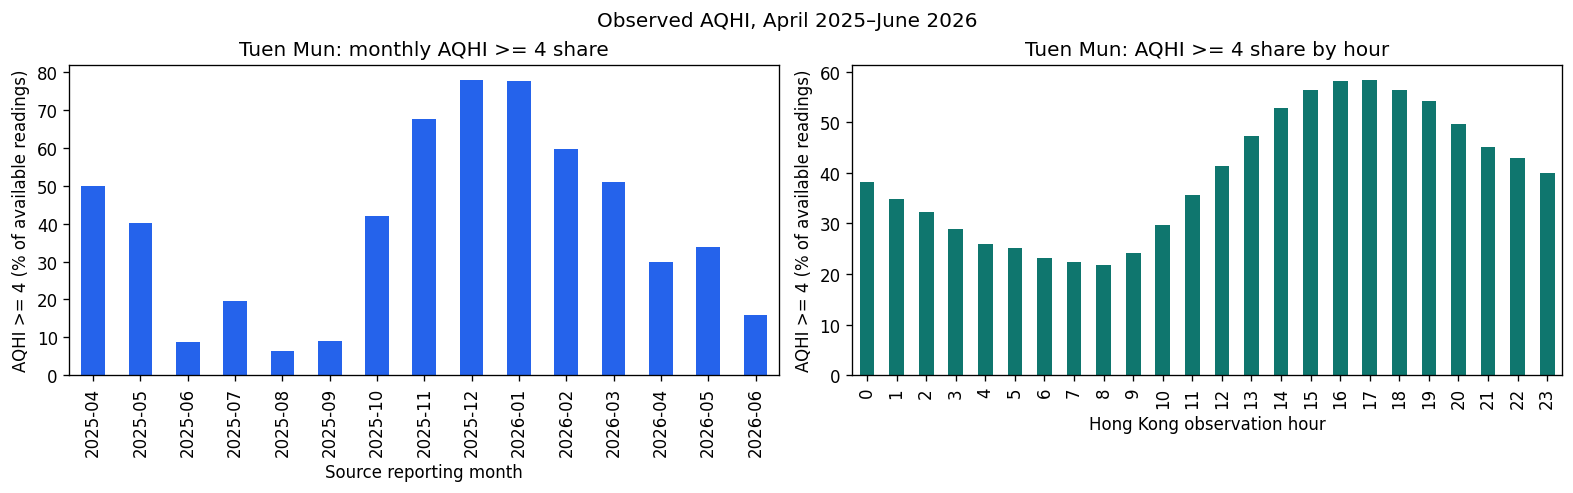

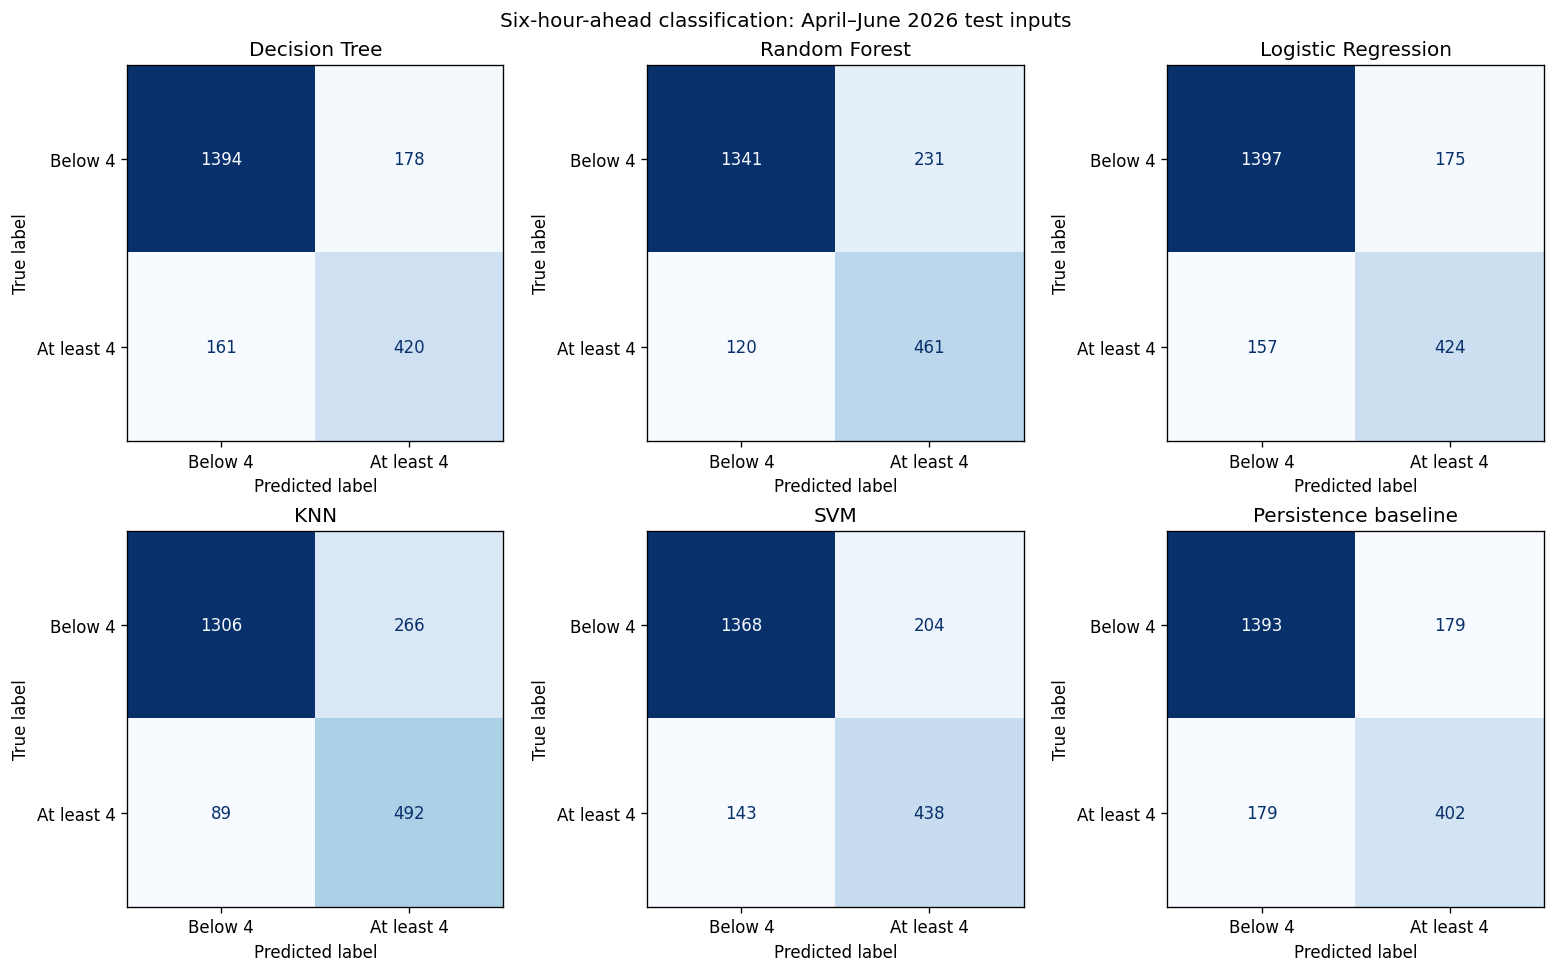

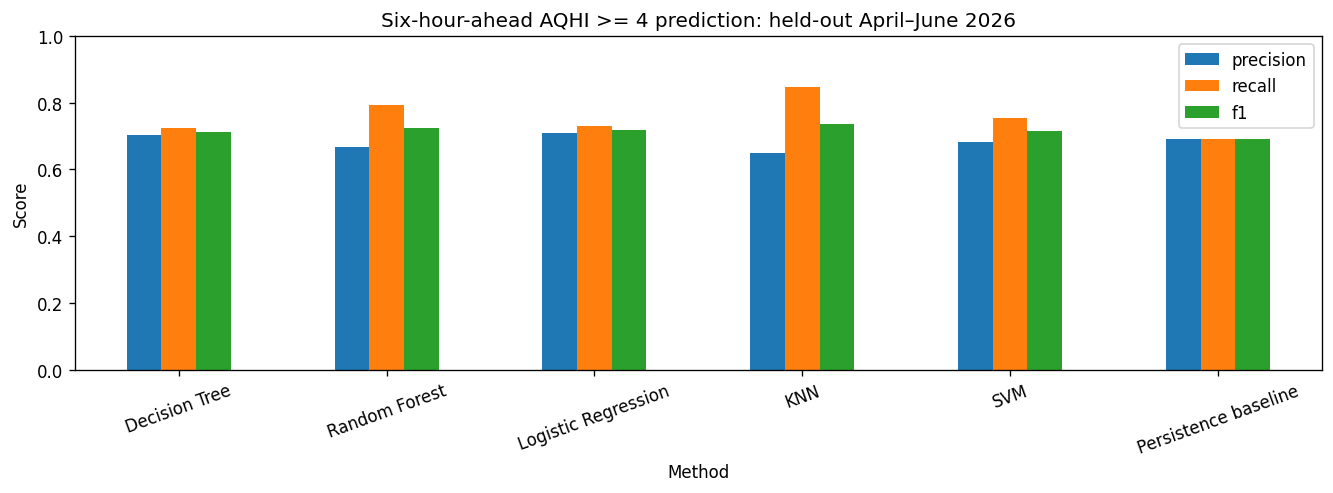

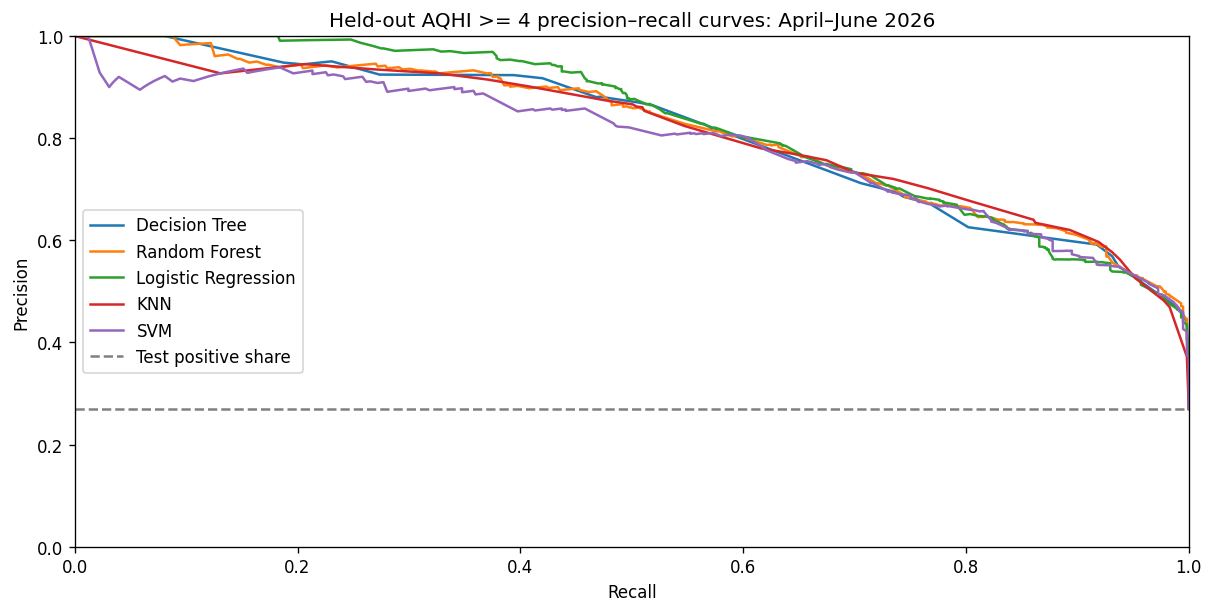

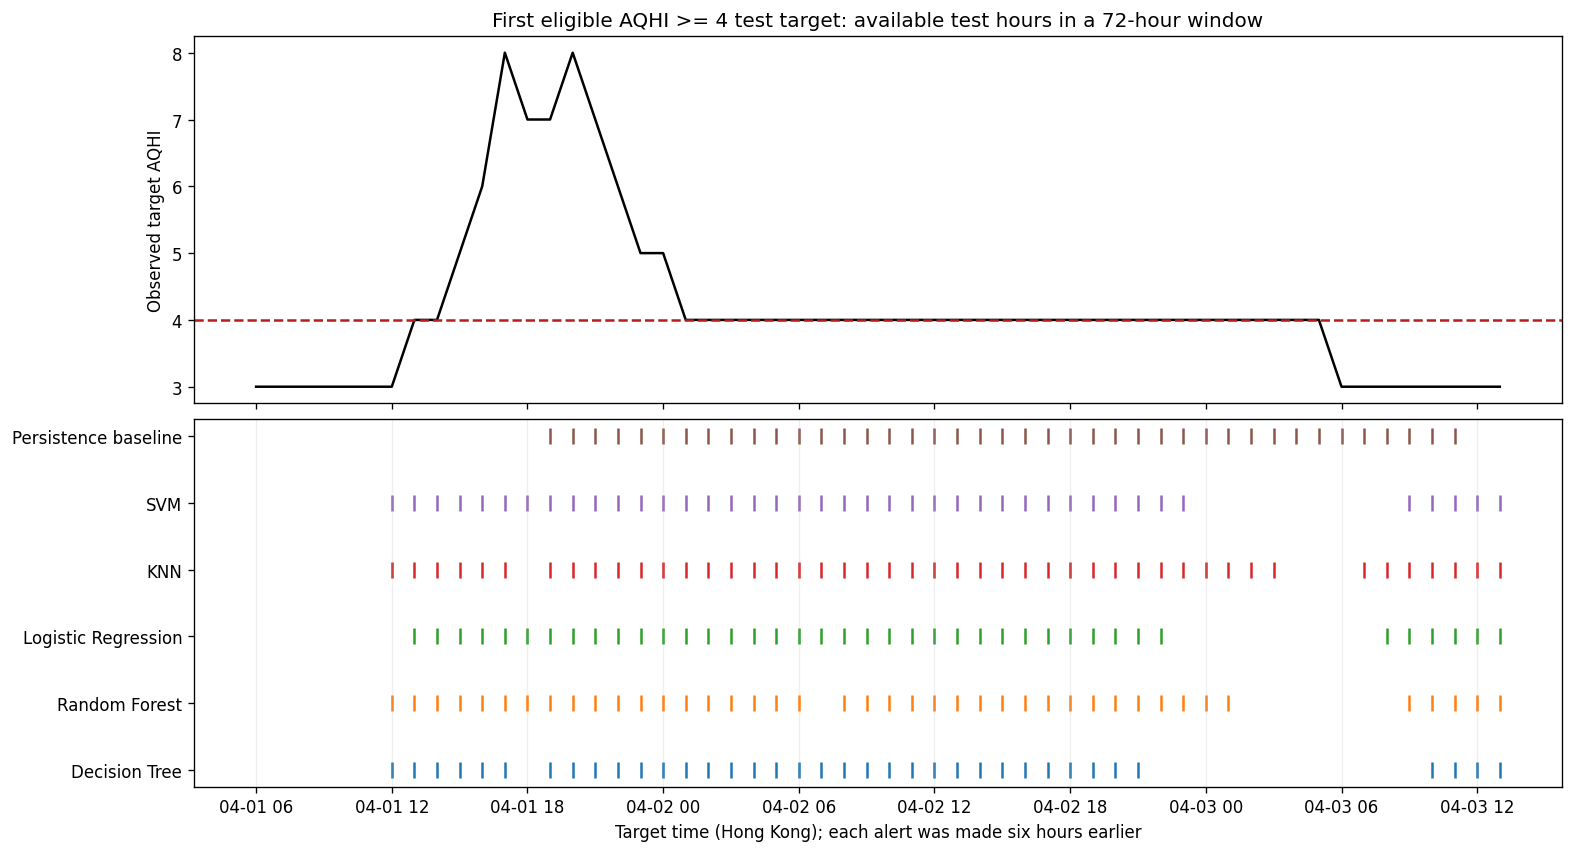

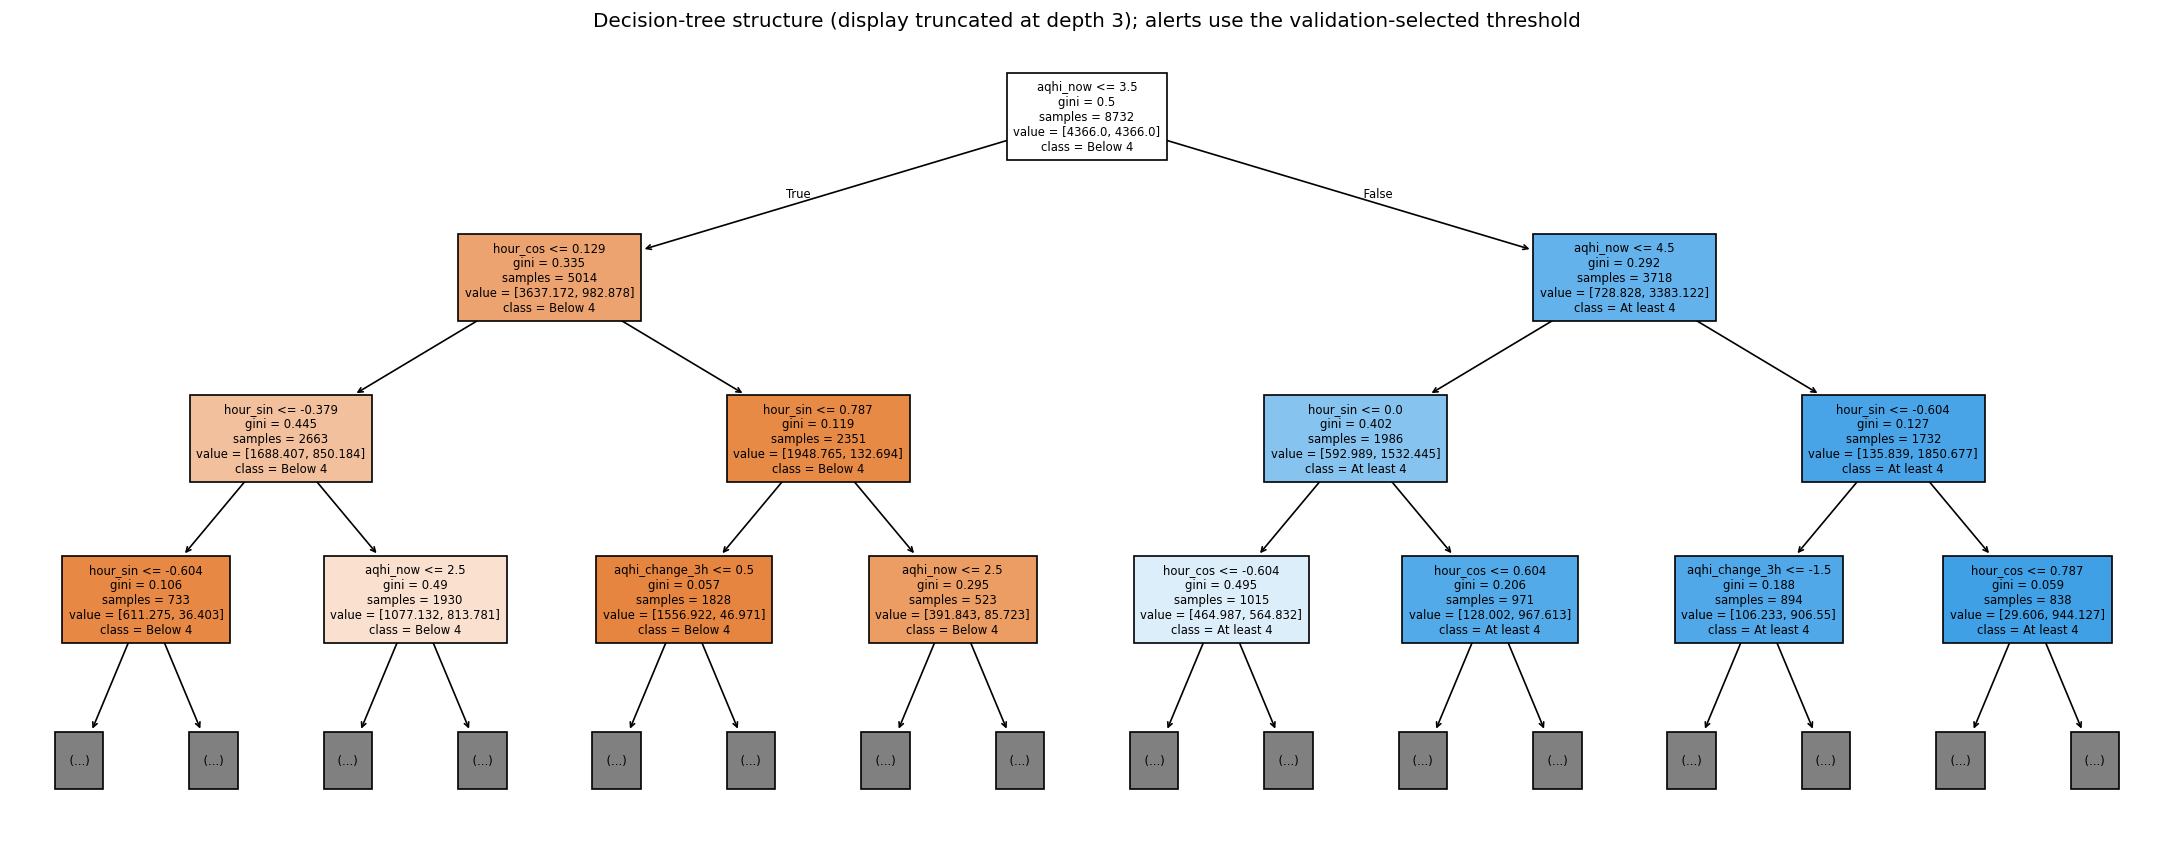

Outputs: /Users/damon/school/26-27/term1/CDS3004/tmp/guided-model/outputs/aqhi4-3h
Validation-selected method: Logistic Regression


In [8]:
monthly = data.assign(month=(data.timestamp - pd.Timedelta(hours=1)).dt.strftime('%Y-%m')).groupby('month').aqhi.agg(
    valid='count', high=lambda s: s.ge(AQHI_THRESHOLD).sum())
hourly = data.assign(hour=data.timestamp.dt.hour).groupby('hour').aqhi.agg(
    valid='count', high=lambda s: s.ge(AQHI_THRESHOLD).sum())
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
(100 * monthly.high / monthly.valid).plot.bar(ax=axes[0], color='#2563eb')
axes[0].set(title='Tuen Mun: monthly AQHI >= 4 share', xlabel='Source reporting month', ylabel='AQHI >= 4 (% of available readings)')
(100 * hourly.high / hourly.valid).plot.bar(ax=axes[1], color='#0f766e')
axes[1].set(title='Tuen Mun: AQHI >= 4 share by hour', xlabel='Hong Kong observation hour', ylabel='AQHI >= 4 (% of available readings)')
fig.suptitle('Observed AQHI, April 2025–June 2026')
fig.savefig(figure_dir / 'aqhi_distribution.png', dpi=160)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout='constrained')
for ax, (name, (_, predicted)) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=[0,1],
        display_labels=['Below 4', 'At least 4'], ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
fig.suptitle('Six-hour-ahead classification: April–June 2026 test inputs')
fig.savefig(figure_dir / 'confusion_matrices.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(11, 4), layout='constrained')
metrics.set_index('method')[['precision','recall','f1']].plot.bar(ax=ax)
ax.set(title='Six-hour-ahead AQHI >= 4 prediction: held-out April–June 2026', ylabel='Score', xlabel='Method', ylim=(0,1))
ax.tick_params(axis='x', labelrotation=20)
fig.savefig(figure_dir / 'model_comparison.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
for name, (scores, _) in predictions.items():
    if name != 'Persistence baseline':
        precision, recall, _ = precision_recall_curve(y_test, scores)
        ax.plot(recall, precision, label=name)
ax.axhline(y_test.mean(), linestyle='--', color='gray', label='Test positive share')
ax.set(title='Held-out AQHI >= 4 precision–recall curves: April–June 2026', xlabel='Recall', ylabel='Precision', xlim=(0,1), ylim=(0,1))
ax.legend()
fig.savefig(figure_dir / 'precision_recall.png', dpi=160)
plt.show()

first_event = test.loc[test.actual_class.eq(1), 'target_time'].iloc[0]
window_start, window_end = first_event - pd.Timedelta(hours=24), first_event + pd.Timedelta(hours=48)
window = test.target_time.between(window_start, window_end)
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, layout='constrained')
axes[0].plot(test.loc[window, 'target_time'], test.loc[window, 'actual_aqhi'], color='black')
axes[0].axhline(AQHI_THRESHOLD, linestyle='--', color='#b91c1c')
axes[0].set(ylabel='Observed target AQHI', title='First eligible AQHI >= 4 test target: available test hours in a 72-hour window')
for position, (name, (_, predicted)) in enumerate(predictions.items()):
    alerts = window.to_numpy() & (predicted == 1)
    axes[1].scatter(test.loc[alerts,'target_time'], np.full(alerts.sum(), position), marker='|', s=90)
axes[1].set(yticks=range(len(predictions)), yticklabels=list(predictions), xlabel='Target time (Hong Kong); each alert was made six hours earlier')
axes[1].grid(axis='x', alpha=0.2)
fig.savefig(figure_dir / 'first_event_timeline.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(18, 7), layout='constrained')
plot_tree(fitted_models['Decision Tree'], feature_names=feature_columns,
          class_names=['Below 4','At least 4'], max_depth=3, filled=True, ax=ax, fontsize=7)
ax.set_title('Decision-tree structure (display truncated at depth 3); alerts use the validation-selected threshold')
fig.savefig(figure_dir / 'decision_tree.png', dpi=160)
plt.show()

run_record = {
    'seed': SEED, 'forecast_hours': 6, 'lookback_hours': 3, 'target_threshold': AQHI_THRESHOLD, 'positive_definition': 'target AQHI >= 4',
    'input_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(),
    'features': feature_columns, 'test_start_inclusive': TEST_START.isoformat(),
    'test_target_end_inclusive': TEST_END.isoformat(),
    'source_hour24': 'next-day midnight, Hong Kong hour endpoint',
    'aqhi_10plus_encoding': 11, 'missing_data': 'complete cases; no interpolation',
    'substitution_policy': 'retain flagged readings; fixed-model subgroup metrics exported',
    'primary_selection_metric': 'pooled chronological validation F1; ties prefer higher precision',
    'validation': {'folds':3, 'gap_rows':6, 'assertion':'fit target times precede validation input times'},
    'selected_models': selected, 'validation_winner': validation_winner,
    'versions': {'python':platform.python_version(), 'pandas':pd.__version__, 'numpy':np.__version__, 'sklearn':sklearn.__version__},
    'test_sample_count':len(test), 'test_positive_count':int(y_test.sum()),
    'timeline_selection':'first eligible positive target, 24h before to 48h after',
}
(output_dir / 'model_settings.json').write_text(json.dumps(run_record, indent=2), encoding='utf-8')
print('Outputs:', output_dir.resolve())
print('Validation-selected method:', validation_winner)

In [9]:
lookback_dir = Path('outputs/aqhi4-lookback-comparison')
lookback_dir.mkdir(parents=True, exist_ok=True)
long_features = features.copy()
for lag in (4, 5, 6):
    long_features[f'aqhi_lag_{lag}h'] = observations['aqhi'].reindex(
        long_features.index - pd.Timedelta(hours=lag)
    ).to_numpy()
long_features['aqhi_change_6h'] = long_features['aqhi_now'] - long_features['aqhi_lag_6h']
six_hour_features = list(long_features.columns)
for lag in range(7, 13):
    long_features[f'aqhi_lag_{lag}h'] = observations['aqhi'].reindex(
        long_features.index - pd.Timedelta(hours=lag)
    ).to_numpy()
long_features['aqhi_change_12h'] = long_features['aqhi_now'] - long_features['aqhi_lag_12h']
lookback_feature_sets = {
    '3h': feature_columns, '6h': six_hour_features, '12h': list(long_features.columns)
}
comparison_samples = long_features.copy()
comparison_samples['target_time'] = comparison_samples.index + HORIZON
comparison_samples['actual_aqhi'] = observations['aqhi'].reindex(comparison_samples.target_time).to_numpy()
comparison_samples = comparison_samples.dropna(subset=list(long_features.columns) + ['actual_aqhi']).copy()
comparison_samples['actual_class'] = comparison_samples.actual_aqhi.ge(AQHI_THRESHOLD).astype(int)
comparison_train = comparison_samples.loc[
    (comparison_samples.index < TEST_START) & (comparison_samples.target_time < TEST_START)
].copy()
comparison_test = comparison_samples.loc[
    (comparison_samples.index >= TEST_START) & (comparison_samples.target_time <= TEST_END)
].copy()
comparison_y_train = comparison_train.actual_class
comparison_y_test = comparison_test.actual_class
comparison_folds = list(TimeSeriesSplit(n_splits=3, gap=6).split(comparison_train))
for fit_rows, validation_rows in comparison_folds:
    assert comparison_train.iloc[fit_rows].target_time.max() < comparison_train.index[validation_rows].min()
    assert comparison_y_train.iloc[fit_rows].nunique() == 2
    assert comparison_y_train.iloc[validation_rows].sum() > 0
assert comparison_train.target_time.max() < comparison_test.index.min()
lookback_split_summary = pd.DataFrame([
    {'split': name, 'samples': len(frame), 'positives': int(frame.actual_class.sum()),
     'first_input': frame.index.min(), 'last_input': frame.index.max(), 'last_target': frame.target_time.max()}
    for name, frame in [('train', comparison_train), ('test', comparison_test)]
])
lookback_split_summary.to_csv(lookback_dir / 'split_summary.csv', index=False)
print(lookback_split_summary.to_string(index=False))
print('Input features:', {name: len(columns) for name, columns in lookback_feature_sets.items()})

split  samples  positives               first_input                last_input               last_target
train     8714       3714 2025-04-01 13:00:00+08:00 2026-03-31 17:00:00+08:00 2026-03-31 23:00:00+08:00
 test     2134        581 2026-04-01 00:00:00+08:00 2026-06-30 18:00:00+08:00 2026-07-01 00:00:00+08:00
Input features: {'3h': 7, '6h': 11, '12h': 18}


In [10]:
lookback_selected = {}
lookback_search_records = []
lookback_metrics_records = []
for lookback, columns in lookback_feature_sets.items():
    fit_X = comparison_train[columns]
    test_X = comparison_test[columns]
    lookback_selected[lookback] = {}
    result_frames = []
    for name, (base_estimator, grid) in model_specs.items():
        candidate_results = []
        for parameters in ParameterGrid(grid):
            fold_scores, fold_truth = [], []
            for fit_rows, validation_rows in comparison_folds:
                estimator = clone(base_estimator).set_params(**parameters)
                estimator.fit(fit_X.iloc[fit_rows], comparison_y_train.iloc[fit_rows])
                fold_scores.extend(scores_for(estimator, fit_X.iloc[validation_rows]))
                fold_truth.extend(comparison_y_train.iloc[validation_rows])
            fold_scores, fold_truth = np.asarray(fold_scores), np.asarray(fold_truth)
            threshold, validation_f1 = select_threshold(fold_truth, fold_scores)
            result = {'lookback': lookback, 'method': name, 'parameters': parameters,
                      'threshold': threshold, 'validation_f1': validation_f1,
                      'validation_precision': precision_score(fold_truth, fold_scores >= threshold, zero_division=0),
                      'validation_recall': recall_score(fold_truth, fold_scores >= threshold, zero_division=0)}
            candidate_results.append(result)
            lookback_search_records.append({**result, 'parameters': json.dumps(parameters, sort_keys=True)})
        best = max(candidate_results, key=lambda r: (r['validation_f1'], r['validation_precision']))
        lookback_selected[lookback][name] = best
        estimator = clone(base_estimator).set_params(**best['parameters'])
        estimator.fit(fit_X, comparison_y_train)
        test_scores = scores_for(estimator, test_X)
        predicted = (test_scores >= best['threshold']).astype(int)
        metric = {'lookback': lookback, **evaluate_predictions(name, comparison_y_test, predicted)}
        metric['average_precision'] = average_precision_score(comparison_y_test, test_scores)
        metric['validation_f1'] = best['validation_f1']
        metric['threshold'] = best['threshold']
        lookback_metrics_records.append(metric)
        frame = comparison_test[['target_time', 'actual_aqhi', 'actual_class']].reset_index()
        frame['lookback'], frame['method'] = lookback, name
        frame['predicted_class'], frame['score'], frame['threshold'] = predicted, test_scores, best['threshold']
        frame['score_type'] = 'decision_function' if name == 'SVM' else 'predict_proba'
        result_frames.append(frame)
        print(lookback, name, 'validation F1:', round(best['validation_f1'], 4), 'test F1:', round(metric['f1'], 4), flush=True)
    baseline_predicted = comparison_test.aqhi_now.ge(AQHI_THRESHOLD).astype(int).to_numpy()
    lookback_metrics_records.append({
        'lookback': lookback, **evaluate_predictions('Persistence baseline', comparison_y_test, baseline_predicted),
        'average_precision': average_precision_score(comparison_y_test, baseline_predicted),
        'validation_f1': np.nan, 'threshold': 0.5})
    baseline_frame = comparison_test[['target_time', 'actual_aqhi', 'actual_class']].reset_index()
    baseline_frame['lookback'], baseline_frame['method'] = lookback, 'Persistence baseline'
    baseline_frame['predicted_class'], baseline_frame['score'], baseline_frame['threshold'] = baseline_predicted, baseline_predicted, 0.5
    baseline_frame['score_type'] = 'binary_baseline'
    result_frames.append(baseline_frame)
    pd.concat(result_frames, ignore_index=True).to_csv(lookback_dir / f'test_predictions_{lookback}.csv', index=False)

lookback_metrics = pd.DataFrame(lookback_metrics_records)
lookback_metrics.to_csv(lookback_dir / 'test_metrics.csv', index=False)
pd.DataFrame(lookback_search_records).to_csv(lookback_dir / 'validation_search.csv', index=False)
paired = lookback_metrics.pivot(index='method', columns='lookback', values=['precision','recall','f1','validation_f1'])
paired.columns = ['_'.join(column) for column in paired.columns]
for hours in (6, 12):
    paired[f'test_f1_change_{hours}h_minus_3h'] = paired[f'f1_{hours}h'] - paired.f1_3h
    paired[f'validation_f1_change_{hours}h_minus_3h'] = paired[f'validation_f1_{hours}h'] - paired.validation_f1_3h
paired.to_csv(lookback_dir / 'paired_comparison.csv')
lookback_validation_choice = max(
    [result for methods in lookback_selected.values() for result in methods.values()],
    key=lambda r: (r['validation_f1'], r['validation_precision'])
)
lookback_settings = {
    'forecast_horizon_hours': 6, 'target_threshold': AQHI_THRESHOLD,
    'positive_definition': 'target AQHI >= 4',
    'feature_sets': lookback_feature_sets,
    'cohort': 'identical complete twelve-hour-history cases for all three lookbacks',
    'test_start': TEST_START.isoformat(), 'test_target_end': TEST_END.isoformat(),
    'validation': 'three expanding chronological folds with six-row gap; all target boundaries checked',
    'selection': 'pooled validation F1; thresholds and parameters retuned separately for each feature set',
    'selected_models': lookback_selected,
    'validation_selected_configuration': lookback_validation_choice,
    'test_interpretation': 'exploratory comparison on an already inspected holdout',
    'train_samples': len(comparison_train), 'test_samples': len(comparison_test),
    'train_positives': int(comparison_y_train.sum()), 'test_positives': int(comparison_y_test.sum()),
    'input_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(),
}
(lookback_dir / 'settings.json').write_text(json.dumps(lookback_settings, indent=2), encoding='utf-8')
print(paired.to_string())
print('Validation-selected configuration:', json.dumps(lookback_validation_choice))

3h Decision Tree validation F1: 0.8225 test F1: 0.7065


3h Random Forest validation F1: 0.8266 test F1: 0.7243


3h Logistic Regression validation F1: 0.8337 test F1: 0.7193


3h KNN validation F1: 0.8161 test F1: 0.7353


3h SVM validation F1: 0.8252 test F1: 0.7163


6h Decision Tree validation F1: 0.823 test F1: 0.7105


... (6 outputs left out)

12h Logistic Regression validation F1: 0.8366 test F1: 0.7051


12h KNN validation F1: 0.8174 test F1: 0.7158


12h SVM validation F1: 0.825 test F1: 0.7232


                      precision_12h  precision_3h  precision_6h  recall_12h  recall_3h  recall_6h    f1_12h     f1_3h     f1_6h  validation_f1_12h  validation_f1_3h  validation_f1_6h  test_f1_change_6h_minus_3h  validation_f1_change_6h_minus_3h  test_f1_change_12h_minus_3h  validation_f1_change_12h_minus_3h
method                                                                                                                                                                                                                                                                                                              
Decision Tree              0.752016      0.710801      0.578378    0.641997   0.702238   0.920826  0.692665  0.706494  0.710491           0.834897          0.822542          0.823018                    0.003998                          0.000476                    -0.013829                           0.012355
KNN                        0.625483      0.648684      0.642105    0.8364

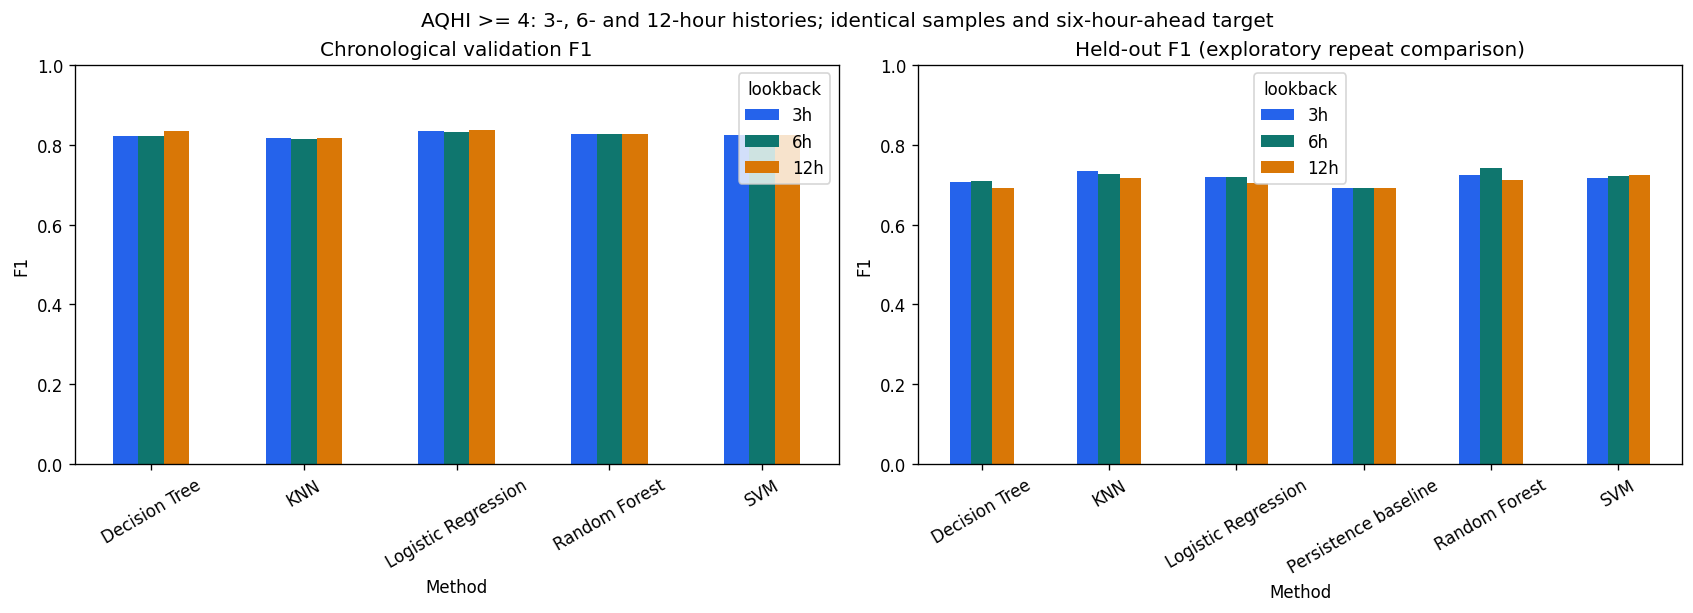

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
for ax, metric_name, title in zip(axes, ['validation_f1','f1'], ['Chronological validation F1', 'Held-out F1 (exploratory repeat comparison)']):
    values = lookback_metrics.pivot(index='method', columns='lookback', values=metric_name)
    if metric_name == 'validation_f1':
        values = values.drop(index='Persistence baseline')
    values = values.reindex(columns=['3h', '6h', '12h'])
    values.plot.bar(ax=ax, color=['#2563eb','#0f766e','#d97706'])
    ax.set(title=title, xlabel='Method', ylabel='F1', ylim=(0, 1))
    ax.tick_params(axis='x', labelrotation=30)
fig.suptitle('AQHI >= 4: 3-, 6- and 12-hour histories; identical samples and six-hour-ahead target')
fig.savefig(lookback_dir / 'lookback_f1_comparison.png', dpi=160)
plt.show()